# Fase 3 — Transformación (KDD)
### Segmentación de caries dentales con SAM 2: construcción de los grupos Control y Experimental

Este notebook implementa la **Fase 3 (Transformación)** descrita en la Sección 3.3.3 del artículo
*"Efecto de un pipeline de preprocesamiento de imágenes intraorales sobre la segmentación de caries dentales condicionada por prompt mediante SAM 2"*.

A partir del corpus auditado de la Fase 2 (**1039 imágenes, 3606 lesiones**), construye dos datasets YOLO idénticos en imágenes, particiones y etiquetas:

- **Control**: imágenes originales, solo con el redimensionado a 1024×1024 que exige SAM 2.
- **Experimental**: las mismas imágenes tras el pipeline determinístico de seis operaciones (Tabla 3 del artículo) y el mismo redimensionado.

El único factor que cambia entre los grupos es el pipeline. El redimensionado (*letterbox* con preservación de la relación de aspecto) se calcula una sola vez por imagen a partir de sus dimensiones originales, por lo que las etiquetas son idénticas en ambos grupos.

| Sección | Contenido | Artículo |
| --- | --- | --- |
| 2 | Entorno y rutas | 3.2.2 |
| 3 | Localización y validación del corpus de entrada | 3.3.3 |
| 4 | Pipeline de seis operaciones | Tabla 3 |
| 5 | Visualización del pipeline y de la atenuación de reflejos | Fig. 3 y Fig. 4 |
| 6 | Letterbox a 1024×1024 | 3.3.3 |
| 7 | Construcción de los grupos Control y Experimental | 3.3.3 |
| 8 | Estadísticas y verificación de paridad | Tabla 2 |
| 9 | Paquete de entregables | — |

Este notebook no entrena modelos ni calcula métricas de desempeño. Su salida alimenta la Fase 4 (ajuste fino de SAM 2).

**Archivos** (carpeta `Fase 3`): `Salida/Control/` y `Salida/Experimental/` (imágenes, etiquetas y `data.yaml`), `phase3_summary.json`, `figuras/` y `Fase3_entregables.zip`.

## 2. Configuración del entorno

Se instalan solo las bibliotecas ausentes en Colab y se monta Google Drive **antes** de definir rutas bajo `/content/drive`.

In [1]:
!pip install -q pyyaml

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import os
import re
import time
import shutil
import json
from pathlib import Path
from dataclasses import dataclass, field
from typing import Optional, Callable

import cv2
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

### 2.1. Configuración centralizada de rutas y parámetros

Las rutas siguen la estructura común del repositorio (`KDD_Caries/Fase N/...`). Para ejecutar el notebook, ajuste `DRIVE` y `OUTPUT_ROOT` a su Google Drive y deje el corpus de la Fase 2 en `Fase 2/Corpus`. Los mensajes impresos usan rutas relativas.

In [4]:
from pathlib import Path

DRIVE = Path("/content/drive/MyDrive")

# Salida de esta ejecución: carpeta "Fase 3" (y la "Fase 2" de la que se lee el corpus)
OUTPUT_ROOT = DRIVE / "KDD_Caries"

# Origen de información previa (opcional)
LEGACY_ROOT = DRIVE / "KDD_Caries" / "previo"

def rel(path) -> str:
    """Ruta legible sin la raíz del Drive (se usa en todos los mensajes impresos)."""
    path = Path(path)
    for root, prefix in ((OUTPUT_ROOT, ""), (LEGACY_ROOT, "previo/")):
        try:
            return prefix + str(path.relative_to(root))
        except ValueError:
            continue
    return path.name

@dataclass(frozen=True)
class Phase3Config:
    """Configuración centralizada de rutas y parámetros de la Fase 3."""

    # --- Corpus de entrada: salida de la Fase 2 (se prueba en este orden) ---
    input_dataset_dirs: tuple = (
        OUTPUT_ROOT / "Fase 2" / "Corpus",
        LEGACY_ROOT / "Fase 2" / "Corpus",
    )
    # Búsqueda recursiva de data.yaml si ninguna de las rutas anteriores lo contiene.
    search_base_dirs: tuple = (OUTPUT_ROOT / "Fase 2", LEGACY_ROOT / "Fase 2")

    # --- Salidas de esta fase ---
    phase_dir: Path = OUTPUT_ROOT / "Fase 3"
    output_root: Path = OUTPUT_ROOT / "Fase 3" / "Salida"
    control_dir: Path = OUTPUT_ROOT / "Fase 3" / "Salida" / "Control"
    experimental_dir: Path = OUTPUT_ROOT / "Fase 3" / "Salida" / "Experimental"
    figures_dir: Path = OUTPUT_ROOT / "Fase 3" / "figuras"

    splits: tuple = ("train", "valid", "test")

    # Ruta relativa (dentro del dataset de entrada) de la imagen usada para la
    # visualización del pipeline. Si es None, se toma la primera de train/images.
    sample_image_relpath: Optional[str] = None

    # Tamaño de entrada requerido por SAM2 y color de relleno del letterbox.
    sam2_input_size: int = 1024
    letterbox_pad_color: tuple = (0, 0, 0)


CONFIG = Phase3Config()

for path in (CONFIG.phase_dir, CONFIG.output_root, CONFIG.control_dir,
             CONFIG.experimental_dir, CONFIG.figures_dir):
    path.mkdir(parents=True, exist_ok=True)

print(f"Corpus de entrada (esperado) : {rel(CONFIG.input_dataset_dirs[0])}")
print(f"Grupo Control                : {rel(CONFIG.control_dir)}")
print(f"Grupo Experimental           : {rel(CONFIG.experimental_dir)}")
print(f"Figuras                      : {rel(CONFIG.figures_dir)}")

Corpus de entrada (esperado) : Fase 2/Corpus
Grupo Control                : Fase 3/Salida/Control
Grupo Experimental           : Fase 3/Salida/Experimental
Figuras                      : Fase 3/figuras


## 3. Localización y validación del corpus de entrada

El corpus de entrada es el que exportó la Fase 2 (`Fase 2/Corpus`): un dataset YOLO con `train/`, `valid/`, `test/` y su `data.yaml`. Si no está en la ruta esperada, se busca de forma recursiva.

In [6]:
class DatasetStructureError(Exception):
    """Error irrecuperable de estructura del dataset de entrada."""


def locate_dataset_dir(config: Phase3Config) -> Path:
    """Devuelve el directorio raíz del corpus de entrada (salida de la Fase 2).
    Prueba las rutas esperadas; si ninguna contiene `data.yaml`, busca
    recursivamente bajo `search_base_dirs`. Si no hay candidatos, detiene la ejecución."""
    for candidate in config.input_dataset_dirs:
        if (candidate / "data.yaml").is_file():
            return candidate

    print("'data.yaml' no encontrado en las rutas esperadas; buscando recursivamente...")
    for base in config.search_base_dirs:
        if base.is_dir():
            matches = sorted(base.rglob("data.yaml"))
            if matches:
                print(f"Dataset localizado en: {rel(matches[0].parent)}")
                return matches[0].parent

    raise DatasetStructureError(
        "No se encontró ningún 'data.yaml' del corpus de la Fase 2."
    )


DATASET_DIR = locate_dataset_dir(CONFIG)
print(f"Corpus de entrada: {rel(DATASET_DIR)}")

Corpus de entrada: Fase 2/Corpus


In [7]:
def validate_dataset_structure(dataset_dir: Path, splits: tuple) -> None:
    data_yaml_path = dataset_dir / "data.yaml"
    if not data_yaml_path.is_file():
        raise DatasetStructureError(
            f"No se encontró 'data.yaml' en '{dataset_dir}'. "
            "La Fase 3 requiere un dataset YOLO válido como entrada."
        )

    missing = []
    for split in splits:
        images_dir = dataset_dir / split / "images"
        labels_dir = dataset_dir / split / "labels"
        if not images_dir.is_dir():
            missing.append(str(images_dir))
        if not labels_dir.is_dir():
            missing.append(str(labels_dir))

    if missing:
        raise DatasetStructureError(
            "La estructura del dataset de entrada es inválida. "
            "Faltan las siguientes carpetas obligatorias:\n"
            + "\n".join(f"  - {path}" for path in missing)
        )

    print(f"Estructura del dataset validada correctamente en: {rel(dataset_dir)}")


validate_dataset_structure(DATASET_DIR, CONFIG.splits)

with open(DATASET_DIR / "data.yaml", "r", encoding="utf-8") as handle:
    INPUT_DATA_YAML = yaml.safe_load(handle)

print("Contenido de data.yaml:", {k: v for k, v in INPUT_DATA_YAML.items() if k != "path"})

Estructura del dataset validada correctamente en: Fase 2/Corpus
Contenido de data.yaml: {'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 1, 'names': ['Caries']}


## 4. Pipeline de optimización visual (Tabla 3)

Se aplica solo al grupo Experimental, en este orden fijo: (1) balance de blancos Shades of Gray, (2) CLAHE sobre el canal L de LAB, (3) atenuación de reflejos especulares, (4) filtro de mediana 3×3, (5) realce de bordes por Laplaciano y (6) ajuste lineal de brillo. Las correcciones de adquisición (iluminante y reflejos) preceden a las operaciones de contraste y de dominio frecuencial, porque estas amplificarían cualquier artefacto fotométrico no corregido.

`PIPELINE_CONFIG` es una lista ordenada de pasos con su bandera `enabled` y sus parámetros. Algunos parámetros no los usa el método activo (por ejemplo `kernel_size` de CLAHE, o los de `bilateral`/`nlm` en la reducción de ruido); se conservan para poder serializar la configuración completa y cambiar de método sin alterar el esquema. **El orden, las operaciones y los valores numéricos son la variable independiente del experimento y no deben modificarse.**

In [8]:
PIPELINE_CONFIG = {
    "pipeline": [
        {
            "operation": "white_balance",
            "enabled": True,
            "method": "shades_of_gray",
            "percentile": 95.0,
            "shades_p": 4.0,
            "saturation_threshold": 0.98
        },
        {
            "operation": "clahe",
            "enabled": True,
            "method": "clahe",
            "color_space": "LAB",
            "clip_limit": 1.3,
            "tile_grid_size": 8,
            "kernel_size": 31
        },
        {
            "operation": "specular_highlight",
            "enabled": True,
            "method": "attenuate",
            "value_threshold": 245,
            "saturation_threshold": 60,
            "dilate": 8,
            "inpaint_radius": 8,
            "attenuation": 0.7
        },
        {
            "operation": "denoise",
            "enabled": True,
            "method": "median_blur",
            "kernel_size": 3,
            "diameter": 7,
            "sigma_color": 120,
            "sigma_space": 120,
            "h": 6.5,
            "template_window": 7,
            "search_window": 21,
            "guided_radius": 8,
            "guided_eps": 0.02
        },
        {
            "operation": "edges",
            "enabled": True,
            "method": "laplacian",
            "kernel_size": 7,
            "threshold1": 83,
            "threshold2": 163,
            "strength": 0.05,
            "overlay": True
        },
        {
            "operation": "brightness_contrast",
            "enabled": True,
            "brightness": -5,
            "contrast": 1.0
        }
    ]
}

print("✅ Configuración del pipeline cargada")

✅ Configuración del pipeline cargada


In [9]:
PIPELINE_STEP_TITLES: dict = {
    "white_balance": "White Balance",
    "clahe": "CLAHE",
    "specular_highlight": "Specular Highlight Attenuation",
    "edges": "Edge Enhancement",
    "denoise": "Denoising",
    "brightness_contrast": "Brightness & Contrast",
}

### 4.1. Auxiliar `_odd`

Varias operaciones de OpenCV exigen kernels impares; `_odd` lleva cualquier entero par al siguiente impar.

In [10]:
def _odd(n: int) -> int:
    """Retorna n si es impar y n+1 si es par (los kernels de OpenCV deben ser impares)."""
    return n if n % 2 == 1 else n + 1

In [11]:
_specular_cfg = next(s for s in PIPELINE_CONFIG["pipeline"] if s["operation"] == "specular_highlight")
_edges_cfg = next(s for s in PIPELINE_CONFIG["pipeline"] if s["operation"] == "edges")
_denoise_cfg = next(s for s in PIPELINE_CONFIG["pipeline"] if s["operation"] == "denoise")

print("Kernels efectivos tras _odd() — valores efectivos de la Tabla 3 del artículo:")
print(f"  specular_highlight.dilate = {_specular_cfg['dilate']} -> kernel efectivo "
      f"{_odd(_specular_cfg['dilate'])}×{_odd(_specular_cfg['dilate'])} "
      f"(sigma del GaussianBlur también = {_odd(_specular_cfg['dilate'])})")
print(f"  edges.kernel_size         = {_edges_cfg['kernel_size']} -> GaussianBlur "
      f"{_odd(_edges_cfg['kernel_size'])}×{_odd(_edges_cfg['kernel_size'])}, "
      f"Laplacian ksize = {min(_odd(_edges_cfg['kernel_size']), 7)}")
print(f"  denoise.kernel_size       = {_denoise_cfg['kernel_size']} -> medianBlur "
      f"{_odd(_denoise_cfg['kernel_size'])}×{_odd(_denoise_cfg['kernel_size'])}")

Kernels efectivos tras _odd() — valores efectivos de la Tabla 3 del artículo:
  specular_highlight.dilate = 8 -> kernel efectivo 9×9 (sigma del GaussianBlur también = 9)
  edges.kernel_size         = 7 -> GaussianBlur 7×7, Laplacian ksize = 7
  denoise.kernel_size       = 3 -> medianBlur 3×3


### 4.2. Operación 1 — Balance de blancos (Shades of Gray)

Estima el iluminante con la norma de Minkowski de orden `shades_p` (4,0) de cada canal, usando todos los píxeles no nulos, y normaliza cada canal contra la media aritmética de las tres normas. Reduce la dominante cromática entre dispositivos antes de cualquier redistribución de contraste.

In [12]:
def _op_white_balance(img_bgr: np.ndarray, cfg: dict) -> np.ndarray:
    """Shades of Gray (Finlayson & Trezzi, 2004): usa todos los píxeles no nulos y la
    media aritmética de las normas por canal como iluminante global."""
    p     = cfg.get("shades_p", 4.0)
    img_f = img_bgr.astype(np.float64)

    norms = []
    for c in range(3):
        ch = img_f[:, :, c].ravel()
        ch = ch[ch > 1e-3]
        if len(ch) == 0:
            norms.append(1.0)
        else:
            norms.append(float((np.mean(ch ** p)) ** (1.0 / p)))

    mean_norm = float(np.mean(norms))   # media aritmética de las tres normas
    result    = img_f.copy()
    for c in range(3):
        n = norms[c] if norms[c] > 0 else 1.0
        result[:, :, c] = np.clip(img_f[:, :, c] * (mean_norm / n), 0.0, 255.0)

    return result.astype(np.uint8)

### 4.3. Operación 2 — CLAHE

Ecualización adaptativa con límite de recorte sobre el canal `L` del espacio LAB (`clip_limit` = 1,3; mosaico 8×8); los canales `a` y `b` no se alteran.

In [13]:
def _op_clahe(img_bgr: np.ndarray, cfg: dict) -> np.ndarray:
    cs   = cfg.get("color_space", "LAB")
    clip = cfg.get("clip_limit", 1.3)
    tile = cfg.get("tile_grid_size", 8)
    clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile))

    if cs == "LAB":
        lab     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(lab)
        return cv2.cvtColor(cv2.merge([clahe.apply(l), a, b]), cv2.COLOR_LAB2BGR)
    elif cs == "HSV":
        hsv     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        h, s, v = cv2.split(hsv)
        return cv2.cvtColor(cv2.merge([h, s, clahe.apply(v)]), cv2.COLOR_HSV2BGR)
    else:
        channels = list(cv2.split(img_bgr))
        return cv2.merge([clahe.apply(c) for c in channels])

### 4.4. Operación 3 — Atenuación de reflejos especulares

Máscara compuesta (criterio HSV `V ≥ 245` y `S ≤ 60`, o pico BGR ≥ 245), dilatada con un kernel elíptico de `_odd(8)` = 9 px. Con el método activo `attenuate`, se suaviza solo la luminancia `L` y se mezcla con peso 0,7 dentro de la máscara; `a` y `b` quedan intactos.

In [14]:
def _op_specular_highlight(img_bgr: np.ndarray, cfg: dict) -> np.ndarray:
    """Atenuación de reflejos especulares (operación 3 de la Tabla 3)."""
    method = cfg.get("method", "attenuate")
    v_thr  = cfg.get("value_threshold", 245)
    s_thr  = cfg.get("saturation_threshold", 60)
    dil_r  = cfg.get("dilate", 8)
    ip_r   = cfg.get("inpaint_radius", 8)
    att    = cfg.get("attenuation", 0.7)

    # Máscara compuesta: criterio HSV (V alto, S bajo) OR pico máximo BGR
    hsv      = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    rgb_peak = img_bgr.max(axis=2)
    mask     = (
        ((hsv[:, :, 2] >= v_thr) & (hsv[:, :, 1] <= s_thr)) |
        (rgb_peak >= v_thr)
    ).astype(np.uint8)

    # Dilatación con kernel _odd(dil_r) × _odd(dil_r)  (9×9 para dil_r=8)
    if dil_r > 0:
        k    = _odd(dil_r)
        kern = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
        mask = cv2.dilate(mask, kern, iterations=1)

    if method == "inpaint":
        return cv2.inpaint(img_bgr, mask, ip_r, cv2.INPAINT_TELEA)

    # Attenuate: trabajar en LAB, suavizar canal L, mezclar solo luminancia
    lab         = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L, a_ch, b_ch = cv2.split(lab)
    L_f         = L.astype(np.float32)

    sigma  = float(_odd(dil_r))
    L_blur = cv2.GaussianBlur(L_f, ksize=(0, 0), sigmaX=sigma, sigmaY=sigma)

    # alpha: en zona especular vale att, fuera vale 0
    alpha  = mask.astype(np.float32) * att
    L_new  = L_f * (1.0 - alpha) + L_blur * alpha
    L_new  = np.clip(L_new, 0, 255).astype(np.uint8)

    return cv2.cvtColor(cv2.merge([L_new, a_ch, b_ch]), cv2.COLOR_LAB2BGR)

### 4.5. Operación 4 — Reducción de ruido

Filtro de mediana de 3×3 (método activo), que atenúa el ruido impulsivo preservando los bordes antes del realce.

In [15]:
def _op_denoise(img_bgr: np.ndarray, cfg: dict) -> np.ndarray:
    method = cfg.get("method", "median_blur")
    ksize  = cfg.get("kernel_size", 3)
    k      = ksize if ksize % 2 == 1 else ksize + 1
    if method == "median_blur":
        return cv2.medianBlur(img_bgr, k)
    elif method == "bilateral":
        return cv2.bilateralFilter(img_bgr, cfg.get("diameter", 7),
                                   cfg.get("sigma_color", 120),
                                   cfg.get("sigma_space", 120))
    elif method == "nlm":
        h = cfg.get("h", 6.5)
        return cv2.fastNlMeansDenoisingColored(
            img_bgr, None, h=h, hColor=h,
            templateWindowSize=cfg.get("template_window", 7),
            searchWindowSize=cfg.get("search_window", 21)
        )
    elif method == "gaussian":
        return cv2.GaussianBlur(img_bgr, (k, k), 0)
    return img_bgr

### 4.6. Operación 5 — Realce de bordes

Laplaciano sobre una versión suavizada en escala de grises (`k` = 7), normalizado a [0, 255] y superpuesto con peso 0,05 para evitar la sobresaturación del contraste.

In [16]:
def _op_edges(img_bgr: np.ndarray, cfg: dict) -> np.ndarray:
    """Realce de bordes: Laplaciano sobre versión suavizada, fusionado con peso `strength`."""
    method   = cfg.get("method", "laplacian")
    ksize    = cfg.get("kernel_size", 7)
    thr1     = cfg.get("threshold1", 83)    # solo usado en método canny
    thr2     = cfg.get("threshold2", 163)
    strength = cfg.get("strength", 0.05)
    overlay  = cfg.get("overlay", True)

    ksize_odd = ksize if ksize % 2 == 1 else ksize + 1
    gray      = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    blurred   = cv2.GaussianBlur(gray, (ksize_odd, ksize_odd), 0)

    if method == "laplacian":
        lap_ksize = min(ksize_odd, 7)
        lap  = cv2.Laplacian(blurred, cv2.CV_64F, ksize=lap_ksize)
        edge = np.abs(lap)
        # normalización min-max a [0, 255], sin recorte por umbral
        norm = np.zeros_like(edge)
        cv2.normalize(edge, norm, 0, 255, cv2.NORM_MINMAX)
        edge = norm.astype(np.uint8)
    else:  # canny
        edge = cv2.Canny(blurred, thr1, thr2)

    if not overlay:
        return cv2.cvtColor(edge, cv2.COLOR_GRAY2BGR)

    edge_bgr = cv2.cvtColor(edge, cv2.COLOR_GRAY2BGR).astype(np.float32)
    result   = img_bgr.astype(np.float32) + strength * edge_bgr
    return np.clip(result, 0, 255).astype(np.uint8)

### 4.7. Operación 6 — Brillo y contraste

Ajuste lineal leve (`brillo` = −5, `alpha` = 1,0) mediante `cv2.convertScaleAbs`, que normaliza la exposición global sin modificar el contraste.

In [17]:
def _op_brightness_contrast(img_bgr: np.ndarray, cfg: dict) -> np.ndarray:
    """Ajuste lineal de brillo/contraste (salida = alpha·entrada + beta, saturado a 8 bits)."""
    return cv2.convertScaleAbs(
        img_bgr,
        alpha=cfg.get("contrast", 1.0),
        beta=cfg.get("brightness", 0),
    )

### 4.8. Orquestación

`preprocesar_imagen()` recorre los pasos en el orden de `PIPELINE_CONFIG`, omite los deshabilitados y avisa (sin detenerse) ante operaciones desconocidas.

In [18]:
_OP_MAP = {
    "white_balance"      : _op_white_balance,
    "clahe"              : _op_clahe,
    "specular_highlight" : _op_specular_highlight,
    "edges"              : _op_edges,
    "denoise"            : _op_denoise,
    "brightness_contrast": _op_brightness_contrast,
}

def preprocesar_imagen(img_bgr: np.ndarray,
                        pipeline_config: dict = None) -> np.ndarray:
    """Aplica el pipeline de preprocesamiento visual configurable por JSON."""
    if pipeline_config is None:
        pipeline_config = PIPELINE_CONFIG
    img = img_bgr.copy()
    for step in pipeline_config["pipeline"]:
        if not step.get("enabled", True):
            continue
        op = step.get("operation", "")
        if op in _OP_MAP:
            img = _OP_MAP[op](img, step)
        else:
            print(f"⚠️ Operación desconocida: '{op}' — omitida")
    return img

print("✅ Pipeline de preprocesamiento visual definido (6 operaciones)")

✅ Pipeline de preprocesamiento visual definido (6 operaciones)


## 5. Visualización del pipeline

Material gráfico para documentar el pipeline. No afecta a los grupos Control y Experimental.

### 5.1. Imágenes de ilustración

In [19]:
def select_sample_image(dataset_dir: Path, config: Phase3Config) -> Path:
    if config.sample_image_relpath is not None:
        candidate = dataset_dir / config.sample_image_relpath
        if not candidate.is_file():
            raise FileNotFoundError(f"Imagen de muestra no encontrada: {candidate}")
        return candidate

    train_images_dir = dataset_dir / "train" / "images"
    candidates = sorted(
        p for p in train_images_dir.iterdir()
        if p.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
    if not candidates:
        raise FileNotFoundError(
            f"No se encontraron imágenes en '{train_images_dir}' para la "
            "visualización académica del pipeline."
        )
    return candidates[0]


SAMPLE_IMAGE_PATH = select_sample_image(DATASET_DIR, CONFIG)
print(f"Imagen seleccionada para la visualización académica: {SAMPLE_IMAGE_PATH.name}")

# Imágenes ilustrativas: se prefieren las del artículo; si no están en train, se usa la
# primera imagen de la misma fuente (prefijo roboflow_ / dentalai_).
PREFERRED_SAMPLE_NAMES = ["roboflow_bd48161573.jpg", "dentalai_f52e01f02b.jpg"]


def resolve_sample_names(dataset_dir: Path, preferred: list) -> list:
    train_dir = dataset_dir / "train" / "images"
    names = []
    for name in preferred:
        if (train_dir / name).is_file():
            names.append(name)
            continue
        prefix = name.split("_")[0] + "_"
        fallback = sorted(p.name for p in train_dir.glob(prefix + "*")
                          if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
        if fallback:
            print(f"'{name}' no está en train; se usa '{fallback[0]}'.")
            names.append(fallback[0])
    return names


image_names_to_plot = resolve_sample_names(DATASET_DIR, PREFERRED_SAMPLE_NAMES)
print("Imágenes de ilustración:", image_names_to_plot)

Imagen seleccionada para la visualización académica: dentalai_00285ac60a.jpg
Imágenes de ilustración: ['roboflow_bd48161573.jpg', 'dentalai_f52e01f02b.jpg']


### 5.2. Ejecución paso a paso

Cada imagen se procesa en el orden del pipeline conservando el resultado de cada operación.

In [20]:
def run_pipeline_stepwise(
    image: np.ndarray,
    pipeline_config: dict = PIPELINE_CONFIG,
    titles: dict = PIPELINE_STEP_TITLES,
) -> list[tuple[str, np.ndarray]]:
    """Ejecuta el pipeline paso a paso, devolviendo una lista de tuplas
    (titulo, imagen) que incluye el estado original, cada operación
    habilitada (en el orden en que aparece en la configuración) y el
    resultado final del pipeline completo.
    """
    stages: list[tuple[str, np.ndarray]] = [("Original", image.copy())]

    current = image.copy()
    for step in pipeline_config["pipeline"]:
        if not step.get("enabled", True):
            continue
        op_name = step["operation"]
        current = _OP_MAP[op_name](current, step)
        stages.append((titles[op_name], current.copy()))

    stages.append(("Final Output", current.copy()))
    return stages


sample_bgr = cv2.imread(str(SAMPLE_IMAGE_PATH))
if sample_bgr is None:
    raise FileNotFoundError(f"No se pudo leer la imagen de muestra: {SAMPLE_IMAGE_PATH}")

pipeline_stages = run_pipeline_stepwise(sample_bgr)
print(f"Etapas generadas: {[title for title, _ in pipeline_stages]}")

Etapas generadas: ['Original', 'White Balance', 'CLAHE', 'Specular Highlight Attenuation', 'Denoising', 'Edge Enhancement', 'Brightness & Contrast', 'Final Output']


### 5.3. Figura del pipeline completo (Fig. 3 del artículo)

Un panel por etapa: original, cada operación y salida final.

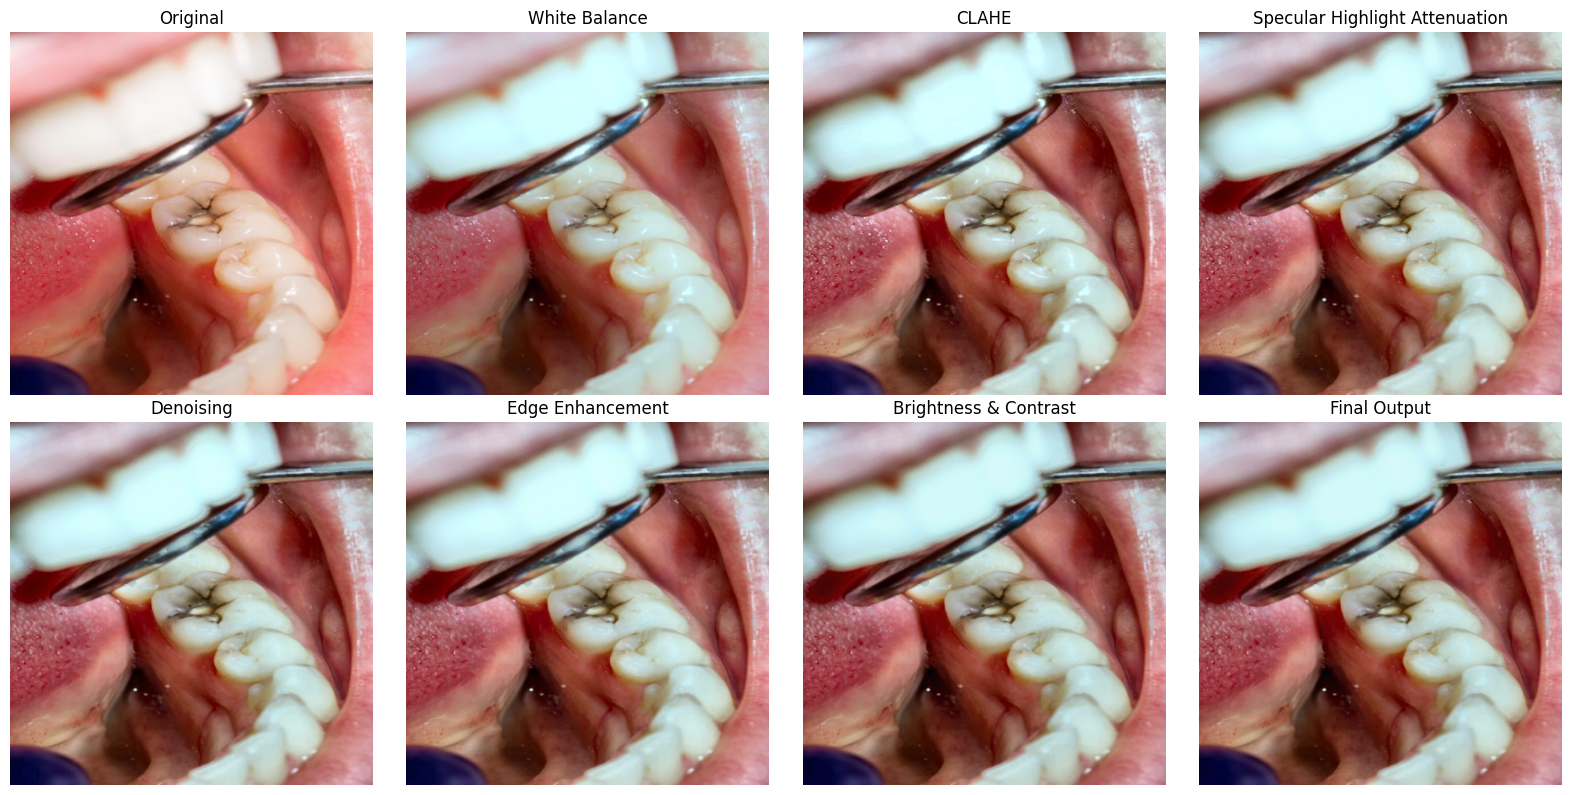

Figura del pipeline para roboflow_bd48161573.jpg guardada en: Fase 3/figuras/Pipeline_Preprocesamiento_roboflow_bd48161573.png


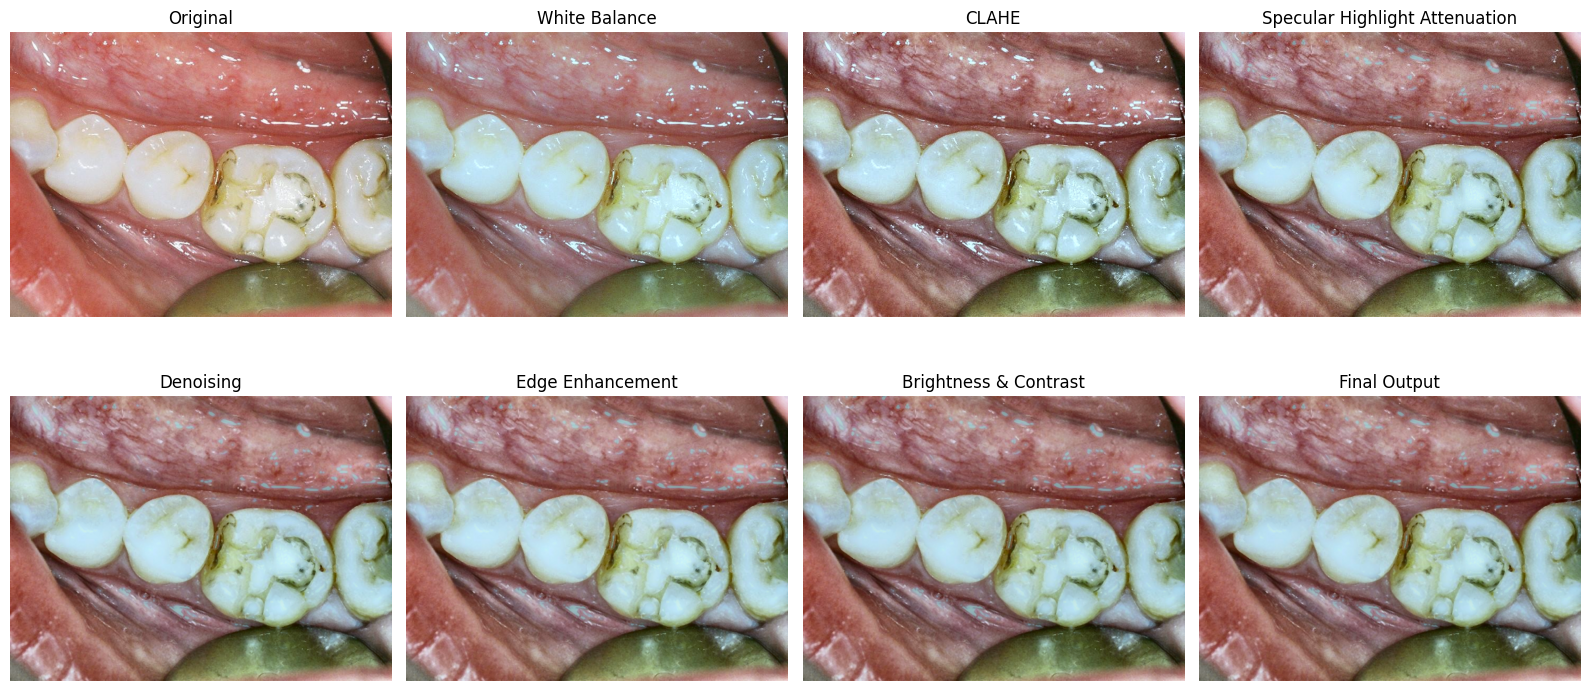

Figura del pipeline para dentalai_f52e01f02b.jpg guardada en: Fase 3/figuras/Pipeline_Preprocesamiento_dentalai_f52e01f02b.png


In [21]:
def plot_pipeline_stages(
    stages: list[tuple[str, np.ndarray]],
    output_path: Path,
    n_cols: int = 4,
    dpi: int = 300,
) -> None:
    n_stages = len(stages)
    n_rows = int(np.ceil(n_stages / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    for ax, (title, image_bgr) in zip(axes, stages):
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        ax.imshow(image_rgb)
        ax.set_title(title, fontsize=12)
        ax.axis("off")

    for ax in axes[n_stages:]:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(output_path, dpi=dpi, bbox_inches="tight")
    plt.show()


for image_name in image_names_to_plot:
    current_image_path = DATASET_DIR / "train" / "images" / image_name
    if not current_image_path.is_file():
        print(f"⚠️  Warning: Image not found: {current_image_path}. Skipping.")
        continue

    current_bgr = cv2.imread(str(current_image_path))
    if current_bgr is None:
        print(f"⚠️  Warning: Could not read image: {current_image_path}. Skipping.")
        continue

    current_pipeline_stages = run_pipeline_stepwise(current_bgr)

    output_filename = f"Pipeline_Preprocesamiento_{Path(image_name).stem}.png"
    output_path = CONFIG.figures_dir / output_filename

    plot_pipeline_stages(
        current_pipeline_stages,
        output_path,
    )
    print(f"Figura del pipeline para {image_name} guardada en: {rel(output_path)}")

### 5.4. Tabla de operaciones y parámetros (Tabla 3 del artículo)

Se construye a partir de `PIPELINE_CONFIG`, de modo que refleja la configuración efectivamente aplicada.

In [22]:
METHOD_DISPLAY: dict = {
    "shades_of_gray": "Shades of Gray",
    "attenuate": "Attenuation",
    "inpaint": "Inpainting",
    "laplacian": "Laplacian",
    "canny": "Canny",
    "median_blur": "Median Blur",
    "bilateral": "Bilateral Filter",
    "nlm": "Non-Local Means",
    "gaussian": "Gaussian Blur",
}


def _method_label(op_name: str, step: dict) -> str:
    if op_name == "clahe":
        return step.get("color_space", "LAB")
    raw_method = step.get("method")
    if raw_method is None:
        return "Linear"  # brightness_contrast no declara "method"
    return METHOD_DISPLAY.get(raw_method, raw_method)


def build_pipeline_summary_table(pipeline_config: dict, titles: dict) -> pd.DataFrame:
    param_summary_by_op = {
        "white_balance": lambda c: f"p={c['shades_p']}",
        "clahe": lambda c: f"canal L; clip={c['clip_limit']}; {c['tile_grid_size']}x{c['tile_grid_size']}",
        "specular_highlight": lambda c: (f"suavizado selectivo L; V>={c['value_threshold']}; "
                                         f"S<={c['saturation_threshold']}; dil={c['dilate']}; att={c['attenuation']}"),
        "denoise": lambda c: f"kernel={c['kernel_size']}",
        "edges": lambda c: f"k={c['kernel_size']}; peso={c['strength']}",
        "brightness_contrast": lambda c: f"brillo={c['brightness']}; alpha={c['contrast']}",
    }

    rows = []
    step_idx = 0
    for step in pipeline_config["pipeline"]:
        if not step.get("enabled", True):
            continue
        step_idx += 1
        op_name = step["operation"]
        rows.append({
            "Paso": step_idx,
            "Operación": titles[op_name],
            "Método": _method_label(op_name, step),
            "Parámetros principales": param_summary_by_op[op_name](step),
        })

    return pd.DataFrame(rows)


pipeline_summary_df = build_pipeline_summary_table(PIPELINE_CONFIG, PIPELINE_STEP_TITLES)
pipeline_summary_df

,Paso,Operación,Método,Parámetros principales
0,1,White Balance,Shades of Gray,p=4.0
1,2,CLAHE,LAB,canal L; clip=1.3; 8x8
2,3,Specular Highlight Attenuation,Attenuation,suavizado selectivo L; V>=245; S<=60; dil=8; a...
3,4,Denoising,Median Blur,kernel=3
4,5,Edge Enhancement,Laplacian,k=7; peso=0.05
5,6,Brightness & Contrast,Linear,brillo=-5; alpha=1.0


### 5.5. Localización espacial de la atenuación de reflejos (Fig. 4 del artículo)

Muestra dónde actúa la operación 3: la máscara de reflejos detectados y el mapa de diferencia absoluta antes y después. Permite comprobar que corrige las zonas de brillo sin alterar de forma difusa el resto de la escena.

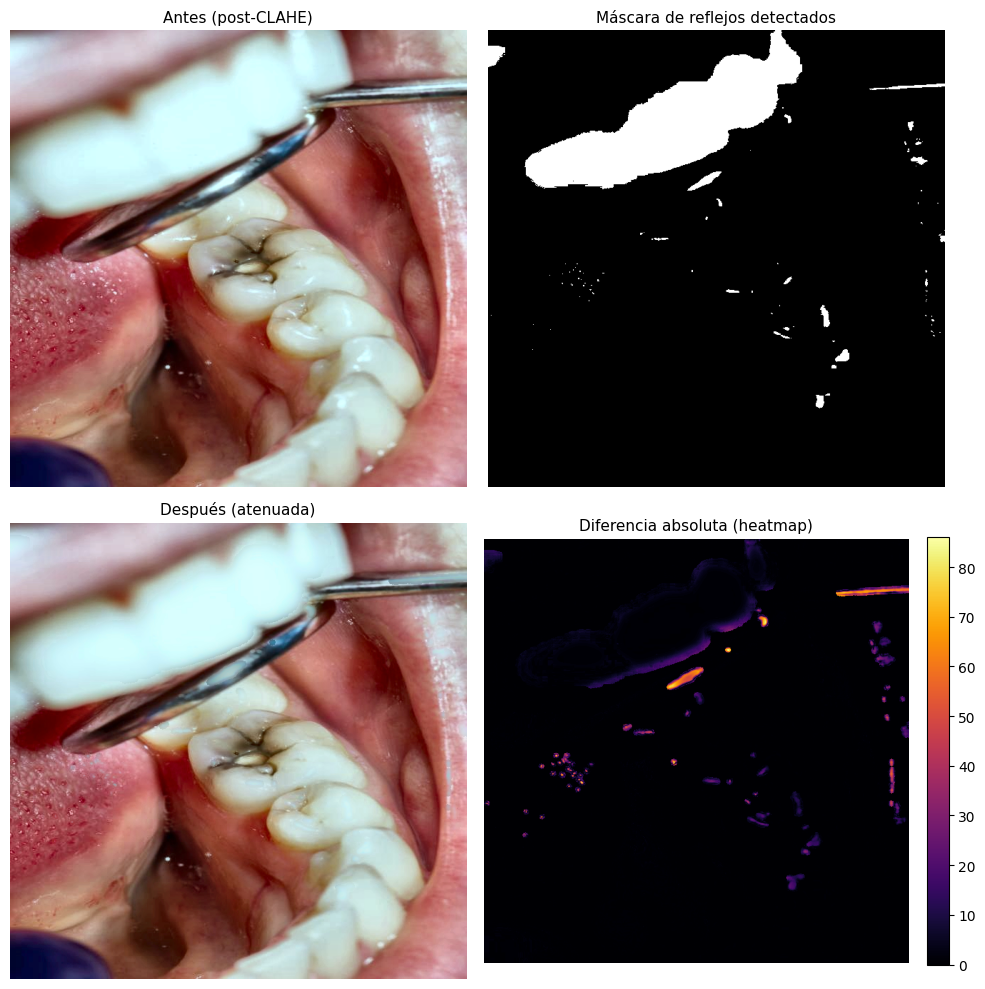

Figura de localización especular para roboflow_bd48161573.jpg guardada en: Fase 3/figuras/Localizacion_Especular_roboflow_bd48161573.png


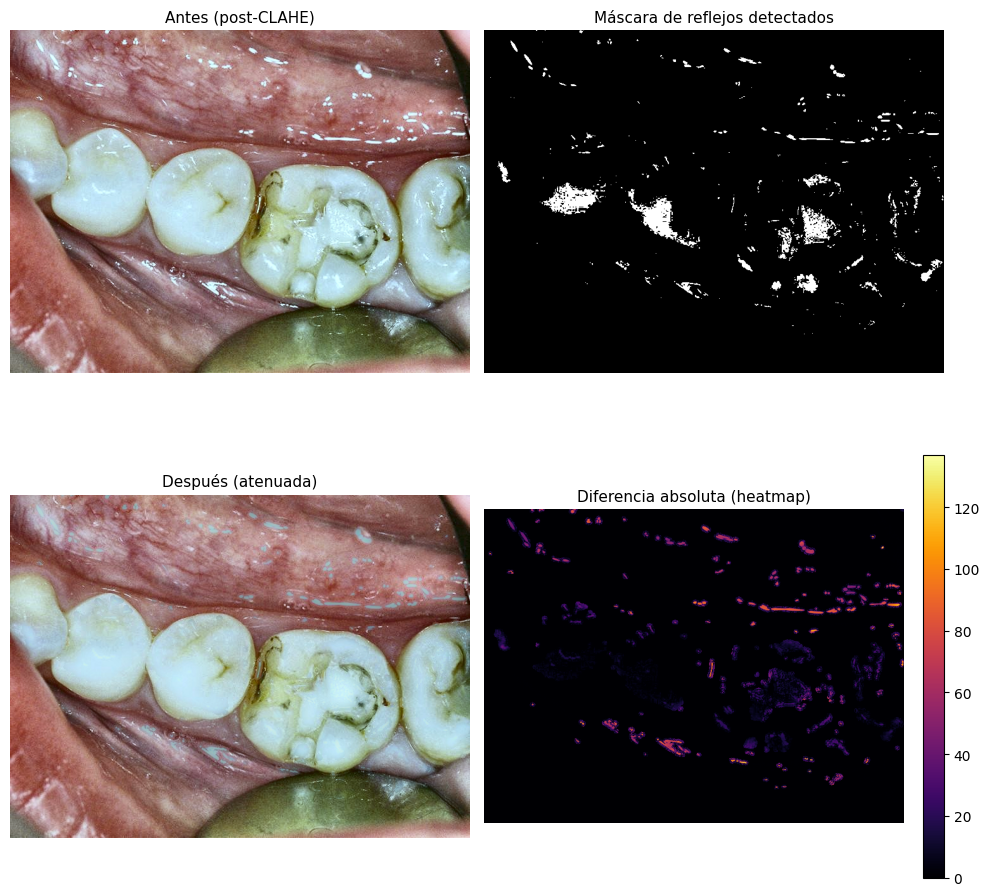

Figura de localización especular para dentalai_f52e01f02b.jpg guardada en: Fase 3/figuras/Localizacion_Especular_dentalai_f52e01f02b.png


In [23]:
def plot_specular_localization(
    stages: list[tuple[str, np.ndarray]],
    cfg: dict,
    output_path: Path,
    dpi: int = 300,
) -> None:
    stages_dict = {title: image for title, image in stages}
    before = stages_dict["CLAHE"]
    after = stages_dict["Specular Highlight Attenuation"]

    v_thr = cfg.get("value_threshold", 245)
    s_thr = cfg.get("saturation_threshold", 60)

    hsv = cv2.cvtColor(before, cv2.COLOR_BGR2HSV)
    rgb_peak = before.max(axis=2)
    mask = (
        ((hsv[:, :, 2] >= v_thr) & (hsv[:, :, 1] <= s_thr)) | (rgb_peak >= v_thr)
    ).astype(np.uint8) * 255

    diff = cv2.absdiff(before, after)
    diff_gray = cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY)

    fig, axes = plt.subplots(2, 2, figsize=(10, 10)) # Changed to 2x2 grid and adjusted figsize for square images
    axes = axes.flatten() # Flatten the 2D array of axes

    axes[0].imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Antes (post-CLAHE)", fontsize=11)

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Máscara de reflejos detectados", fontsize=11)

    axes[2].imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB))
    axes[2].set_title("Después (atenuada)", fontsize=11)

    heatmap = axes[3].imshow(diff_gray, cmap="inferno")
    axes[3].set_title("Diferencia absoluta (heatmap)", fontsize=11)
    fig.colorbar(heatmap, ax=axes[3], fraction=0.046, pad=0.04)

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(output_path, dpi=dpi, bbox_inches="tight")
    plt.show()


_specular_cfg_viz = next(
    s for s in PIPELINE_CONFIG["pipeline"] if s["operation"] == "specular_highlight"
)

for image_name in image_names_to_plot:
    current_image_path = DATASET_DIR / "train" / "images" / image_name
    if not current_image_path.is_file():
        print(f"⚠️  Warning: Image not found: {current_image_path}. Skipping.")
        continue

    current_bgr = cv2.imread(str(current_image_path))
    if current_bgr is None:
        print(f"⚠️  Warning: Could not read image: {current_image_path}. Skipping.")
        continue

    current_stages = run_pipeline_stepwise(current_bgr)

    output_filename = f"Localizacion_Especular_{Path(image_name).stem}.png"
    output_path = CONFIG.figures_dir / output_filename

    plot_specular_localization(current_stages, _specular_cfg_viz, output_path)
    print(f"Figura de localización especular para {image_name} guardada en: {rel(output_path)}")

## 6. Redimensionado homogéneo para SAM 2 (letterbox)

Ambos grupos usan el mismo lienzo de **1024×1024** con preservación de la relación de aspecto (relleno negro). Como el relleno desplaza el contenido, las coordenadas normalizadas de los polígonos se recalculan con la misma transformación, que depende solo de las dimensiones originales. La interpolación se elige según la dirección del escalado: `INTER_AREA` al reducir e `INTER_CUBIC` al ampliar.

### 6.1. Parámetros de letterbox

In [24]:
@dataclass(frozen=True)
class LetterboxParams:
    scale: float
    new_w: int
    new_h: int
    pad_left: int
    pad_top: int


def compute_letterbox_params(orig_h: int, orig_w: int, target_size: int) -> LetterboxParams:
    scale = target_size / max(orig_h, orig_w)
    new_w = int(round(orig_w * scale))
    new_h = int(round(orig_h * scale))

    pad_left = (target_size - new_w) // 2
    pad_top = (target_size - new_h) // 2

    return LetterboxParams(scale=scale, new_w=new_w, new_h=new_h, pad_left=pad_left, pad_top=pad_top)

### 6.2. Aplicación a la imagen

In [25]:
def apply_letterbox(
    image: np.ndarray,
    params: LetterboxParams,
    target_size: int,
    pad_color: tuple,
) -> np.ndarray:
    """Redimensiona con letterbox (relleno `pad_color`). La interpolación depende de la
    dirección del escalado: INTER_AREA al reducir (antialiasing) e INTER_CUBIC al ampliar
    (INTER_AREA degrada la nitidez al ampliar)."""
    interpolation = cv2.INTER_AREA if params.scale < 1.0 else cv2.INTER_CUBIC
    resized = cv2.resize(image, (params.new_w, params.new_h), interpolation=interpolation)

    canvas = np.full((target_size, target_size, 3), pad_color, dtype=np.uint8)
    canvas[
        params.pad_top: params.pad_top + params.new_h,
        params.pad_left: params.pad_left + params.new_w,
    ] = resized
    return canvas

### 6.3. Transformación de las anotaciones YOLO

In [26]:
def read_yolo_label(label_path: Path) -> list[tuple[int, list[float]]]:
    annotations = []
    if not label_path.is_file():
        return annotations
    with open(label_path, "r", encoding="utf-8") as handle:
        for line in handle:
            parts = line.strip().split()
            if not parts:
                continue
            class_id = int(parts[0])
            coords = list(map(float, parts[1:]))
            annotations.append((class_id, coords))
    return annotations


def write_yolo_label(label_path: Path, annotations: list[tuple[int, list[float]]]) -> None:
    lines = []
    for class_id, coords in annotations:
        coords_str = " ".join(f"{c:.6f}" for c in coords)
        lines.append(f"{class_id} {coords_str}")
    label_path.write_text("\n".join(lines), encoding="utf-8")


def transform_annotations_for_letterbox(
    annotations: list[tuple[int, list[float]]],
    orig_w: int,
    orig_h: int,
    params: LetterboxParams,
    target_size: int,
) -> list[tuple[int, list[float]]]:
    """Recalcula las coordenadas normalizadas de cada polígono para que
    permanezcan alineadas con la imagen tras el redimensionado con
    letterbox.
    """
    transformed = []
    for class_id, coords in annotations:
        new_coords = []
        for i in range(0, len(coords), 2):
            x_norm, y_norm = coords[i], coords[i + 1]
            x_abs = x_norm * orig_w
            y_abs = y_norm * orig_h

            x_scaled = x_abs * params.scale + params.pad_left
            y_scaled = y_abs * params.scale + params.pad_top

            new_coords.append(max(0.0, min(1.0, x_scaled / target_size)))
            new_coords.append(max(0.0, min(1.0, y_scaled / target_size)))

        transformed.append((class_id, new_coords))
    return transformed

### 6.4. Figura: original frente a letterbox

Se usa una imagen de Roboflow (640×640), que requiere **ampliación** y es el caso más sensible a la pérdida de nitidez.

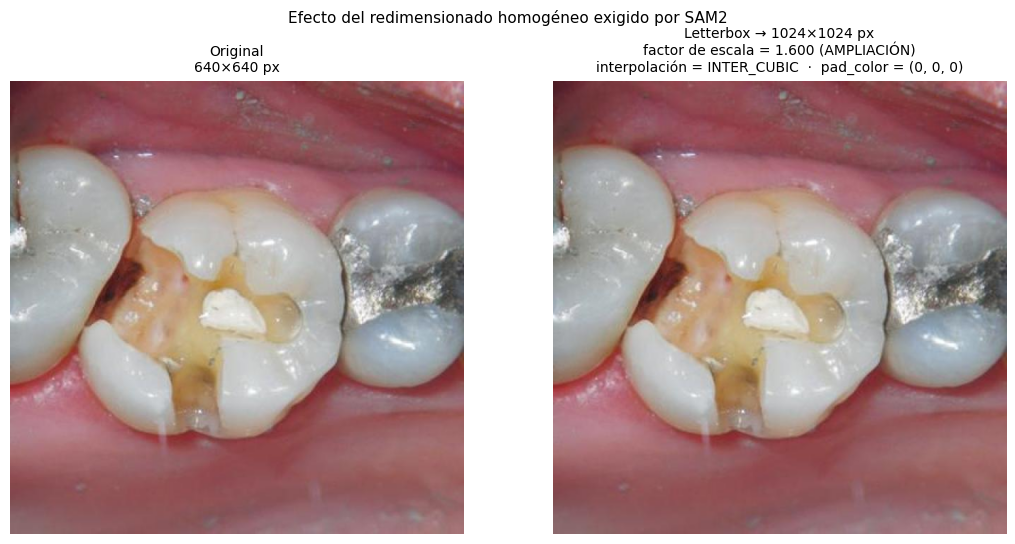

In [27]:
def plot_letterbox_comparison(
    image_path: Path,
    target_size: int,
    pad_color: tuple,
    save_path: Optional[Path] = None,
) -> None:
    """Muestra la imagen original junto a su resultado tras letterbox,
    anotando el factor de escala y el método de interpolación usado.
    """
    original = cv2.imread(str(image_path))
    orig_h, orig_w = original.shape[:2]

    params = compute_letterbox_params(orig_h, orig_w, target_size)
    resized = apply_letterbox(original, params, target_size, pad_color)

    direction = "AMPLIACIÓN" if params.scale >= 1.0 else "reducción"
    interp = "INTER_CUBIC" if params.scale >= 1.0 else "INTER_AREA"

    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))

    axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Original\n{orig_w}×{orig_h} px", fontsize=10)
    axes[0].axis("off")

    axes[1].imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
    axes[1].set_title(
        f"Letterbox → {target_size}×{target_size} px\n"
        f"factor de escala = {params.scale:.3f} ({direction})\n"
        f"interpolación = {interp}  ·  pad_color = {pad_color}",
        fontsize=10,
    )
    axes[1].axis("off")

    plt.suptitle("Efecto del redimensionado homogéneo exigido por SAM2", fontsize=11)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


# Se busca deliberadamente una muestra de Roboflow (640×640 fijo) para
# ilustrar el caso de AMPLIACIÓN, el más sensible a pérdida de nitidez.
_sample_upscale_candidates = sorted(
    (DATASET_DIR / "train" / "images").glob("roboflow_*")
)
_demo_image_path = (
    _sample_upscale_candidates[0] if _sample_upscale_candidates
    else select_sample_image(DATASET_DIR, CONFIG)
)

plot_letterbox_comparison(
    _demo_image_path,
    target_size=CONFIG.sam2_input_size,
    pad_color=CONFIG.letterbox_pad_color,
    save_path=CONFIG.figures_dir / "Comparacion_Original_vs_Letterbox.png",
)

## 7. Construcción de los grupos Control y Experimental

Se recorren las particiones `train`, `valid` y `test`. Para cada muestra, los parámetros de letterbox se calculan una vez y se aplican a ambos grupos; las etiquetas transformadas son idénticas.

### 7.1. Estructura de salida y `data.yaml`

In [28]:
def prepare_output_structure(output_dir: Path, splits: tuple) -> None:
    for split in splits:
        (output_dir / split / "images").mkdir(parents=True, exist_ok=True)
        (output_dir / split / "labels").mkdir(parents=True, exist_ok=True)


def write_group_data_yaml(source_data_yaml: dict, output_dir: Path) -> None:
    group_yaml = dict(source_data_yaml)
    group_yaml["path"] = str(output_dir)
    group_yaml["train"] = "train/images"
    group_yaml["val"] = "valid/images"
    group_yaml["test"] = "test/images"

    with open(output_dir / "data.yaml", "w", encoding="utf-8") as handle:
        yaml.safe_dump(group_yaml, handle, sort_keys=False, allow_unicode=True)


prepare_output_structure(CONFIG.control_dir, CONFIG.splits)
prepare_output_structure(CONFIG.experimental_dir, CONFIG.splits)

write_group_data_yaml(INPUT_DATA_YAML, CONFIG.control_dir)
write_group_data_yaml(INPUT_DATA_YAML, CONFIG.experimental_dir)

print(f"Estructura de salida preparada en: {rel(CONFIG.control_dir)}")
print(f"Estructura de salida preparada en: {rel(CONFIG.experimental_dir)}")

Estructura de salida preparada en: Fase 3/Salida/Control
Estructura de salida preparada en: Fase 3/Salida/Experimental


### 7.2. Procesamiento de una muestra

In [29]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")


def process_single_sample(
    image_path: Path,
    label_path: Path,
    control_dir: Path,
    experimental_dir: Path,
    split: str,
    target_size: int,
    pad_color: tuple,
) -> tuple[str, float, Optional[str], Optional[float]]:
    """Procesa una muestra para ambos grupos. Devuelve (estado, segundos_del_pipeline,
    direccion_escalado, factor_escala); estado es 'ok', 'omitida' o 'error'."""
    if not label_path.is_file():
        return "omitida", 0.0, None, None

    original = cv2.imread(str(image_path))
    if original is None:
        return "error", 0.0, None, None

    orig_h, orig_w = original.shape[:2]
    letterbox_params = compute_letterbox_params(orig_h, orig_w, target_size)
    scale_direction = "ampliacion" if letterbox_params.scale >= 1.0 else "reduccion"
    interpolation_used = "INTER_CUBIC" if letterbox_params.scale >= 1.0 else "INTER_AREA"

    annotations = read_yolo_label(label_path)
    transformed_annotations = transform_annotations_for_letterbox(
        annotations, orig_w, orig_h, letterbox_params, target_size
    )

    # --- Grupo Control: imagen original + letterbox, sin mejora visual ---
    control_image = apply_letterbox(original, letterbox_params, target_size, pad_color)
    control_image_path = control_dir / split / "images" / image_path.name
    control_label_path = control_dir / split / "labels" / f"{image_path.stem}.txt"
    cv2.imwrite(str(control_image_path), control_image)
    write_yolo_label(control_label_path, transformed_annotations)

    # --- Grupo Experimental: pipeline visual completo + letterbox ---
    pipeline_start = time.perf_counter()
    enhanced = preprocesar_imagen(original.copy())
    pipeline_elapsed = time.perf_counter() - pipeline_start

    experimental_image = apply_letterbox(enhanced, letterbox_params, target_size, pad_color)
    experimental_image_path = experimental_dir / split / "images" / image_path.name
    experimental_label_path = experimental_dir / split / "labels" / f"{image_path.stem}.txt"
    cv2.imwrite(str(experimental_image_path), experimental_image)
    write_yolo_label(experimental_label_path, transformed_annotations)

    return "ok", pipeline_elapsed, scale_direction, letterbox_params.scale

### 7.3. Recorrido del corpus completo

El pipeline se aplica a la imagen en su resolución original (hasta 8688 px de ancho), antes del redimensionado, por lo que esta celda puede tardar.

In [30]:
processing_log: list[dict] = []

for split in CONFIG.splits:
    images_dir = DATASET_DIR / split / "images"
    labels_dir = DATASET_DIR / split / "labels"

    image_paths = sorted(
        p for p in images_dir.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS
    )
    print(f"[{split}] {len(image_paths)} imágenes encontradas.")

    for image_path in tqdm(image_paths, desc=f"Procesando {split}"):
        label_path = labels_dir / f"{image_path.stem}.txt"

        status, elapsed, scale_direction, scale_factor = process_single_sample(
            image_path=image_path,
            label_path=label_path,
            control_dir=CONFIG.control_dir,
            experimental_dir=CONFIG.experimental_dir,
            split=split,
            target_size=CONFIG.sam2_input_size,
            pad_color=CONFIG.letterbox_pad_color,
        )

        processing_log.append({
            "split": split,
            "sample": image_path.name,
            "status": status,
            "pipeline_seconds": elapsed,
            "direccion_escalado": scale_direction,
            "factor_escala": scale_factor,
        })

processing_df = pd.DataFrame(processing_log)
processing_df["status"].value_counts()

[train] 727 imágenes encontradas.


Procesando train:   0%|          | 0/727 [00:00<?, ?it/s]

[valid] 156 imágenes encontradas.


Procesando valid:   0%|          | 0/156 [00:00<?, ?it/s]

[test] 156 imágenes encontradas.


Procesando test:   0%|          | 0/156 [00:00<?, ?it/s]

,count
status,
ok,1039


## 8. Estadísticas y verificación de paridad

### 8.1. Resumen de la fase

In [31]:
def build_phase3_summary(processing_df: pd.DataFrame) -> dict:
    ok_df = processing_df[processing_df["status"] == "ok"]

    scaling_counts = ok_df["direccion_escalado"].value_counts().to_dict()

    return {
        "total_imagenes_encontradas": int(len(processing_df)),
        "imagenes_por_particion": processing_df.groupby("split").size().to_dict(),
        "imagenes_procesadas_ok": int(len(ok_df)),
        "imagenes_copiadas_grupo_control": int(len(ok_df)),
        "imagenes_procesadas_grupo_experimental": int(len(ok_df)),
        "imagenes_omitidas": int((processing_df["status"] == "omitida").sum()),
        "imagenes_con_error": int((processing_df["status"] == "error").sum()),
        "tiempo_total_pipeline_visual_segundos": float(ok_df["pipeline_seconds"].sum()),
        "tiempo_promedio_por_imagen_segundos": (
            float(ok_df["pipeline_seconds"].mean()) if len(ok_df) > 0 else 0.0
        ),
        "imagenes_ampliadas_hacia_1024": int(scaling_counts.get("ampliacion", 0)),
        "imagenes_reducidas_hacia_1024": int(scaling_counts.get("reduccion", 0)),
        "factor_escala_promedio": float(ok_df["factor_escala"].mean()) if len(ok_df) > 0 else 0.0,
        "metodo_interpolacion_ampliacion": "INTER_CUBIC",
        "metodo_interpolacion_reduccion": "INTER_AREA",
        "letterbox_pad_color": list(CONFIG.letterbox_pad_color),
    }


phase3_summary = build_phase3_summary(processing_df)

with open(CONFIG.phase_dir / "phase3_summary.json", "w", encoding="utf-8") as handle:
    json.dump(phase3_summary, handle, indent=2, ensure_ascii=False)

phase3_summary

{'total_imagenes_encontradas': 1039,
 'imagenes_por_particion': {'test': 156, 'train': 727, 'valid': 156},
 'imagenes_procesadas_ok': 1039,
 'imagenes_copiadas_grupo_control': 1039,
 'imagenes_procesadas_grupo_experimental': 1039,
 'imagenes_omitidas': 0,
 'imagenes_con_error': 0,
 'tiempo_total_pipeline_visual_segundos': 1223.8946915060042,
 'tiempo_promedio_por_imagen_segundos': 1.177954467282006,
 'imagenes_ampliadas_hacia_1024': 547,
 'imagenes_reducidas_hacia_1024': 492,
 'factor_escala_promedio': 0.9313208221492885,
 'metodo_interpolacion_ampliacion': 'INTER_CUBIC',
 'metodo_interpolacion_reduccion': 'INTER_AREA',
 'letterbox_pad_color': [0, 0, 0]}

### 8.2. Conteo de lesiones y paridad entre grupos

Cada línea de un `.txt` YOLO es una lesión. Se comprueba que Control y Experimental tengan las mismas imágenes y lesiones por partición y se contrasta el total con el artículo (3606 lesiones; 156 imágenes y 564 lesiones en prueba).

In [32]:
def contar_lesiones_por_grupo(directorio_grupo: Path, splits: tuple):
    """Cuenta imágenes y lesiones (una línea = un polígono) por partición, sin reprocesar imágenes."""
    resultados = {}
    for split in splits:
        por_imagen = {}
        for label_path in (directorio_grupo / split / "labels").glob("*.txt"):
            with open(label_path, "r", encoding="utf-8") as handle:
                por_imagen[label_path.stem] = sum(1 for line in handle if line.strip())
        resultados[split] = por_imagen
    return resultados


conteo_control = contar_lesiones_por_grupo(CONFIG.control_dir, CONFIG.splits)
conteo_experimental = contar_lesiones_por_grupo(CONFIG.experimental_dir, CONFIG.splits)

# Paridad: Control y Experimental deben tener las mismas imágenes y el mismo número de lesiones por partición.
for split in CONFIG.splits:
    assert conteo_control[split] == conteo_experimental[split], f"Desbalance entre grupos en {split}"
print("Paridad Control vs Experimental verificada (mismas imágenes y mismas lesiones por partición).\n")

rows = []
for split in CONFIG.splits:
    counts = np.array(list(conteo_control[split].values()))
    rows.append({"partición": split, "imágenes": len(counts), "lesiones": int(counts.sum()),
                 "media les./img": round(float(counts.mean()), 2), "máx. les./img": int(counts.max()),
                 "imgs. con >1 lesión": int((counts > 1).sum())})
all_counts = {name: n for split in CONFIG.splits for name, n in conteo_control[split].items()}
arr = np.array(list(all_counts.values()))
rows.append({"partición": "TOTAL", "imágenes": len(arr), "lesiones": int(arr.sum()),
             "media les./img": round(float(arr.mean()), 2), "máx. les./img": int(arr.max()),
             "imgs. con >1 lesión": int((arr > 1).sum())})
df_instancias = pd.DataFrame(rows)
print(df_instancias.to_string(index=False))

# Lesiones por imagen según la fuente (el prefijo del nombre identifica el origen)
for prefix, label in (("dentalai_", "DentalAI"), ("roboflow_", "Roboflow")):
    vals = [n for name, n in all_counts.items() if name.startswith(prefix)]
    print(f"{label}: {len(vals)} imágenes, {sum(vals)} lesiones, {np.mean(vals):.1f} lesiones por imagen")

# Verificación contra el artículo (Tablas 1-2 y Sección 3.3.4): solo informa, no detiene la ejecución.
esperado = {"imágenes": 1039, "lesiones": 3606, "imgs. con >1 lesión": 733}
total_row = df_instancias[df_instancias["partición"] == "TOTAL"].iloc[0]
test_row = df_instancias[df_instancias["partición"] == "test"].iloc[0]
avisos = [f"{k}: obtenido {int(total_row[k])}, artículo {v}" for k, v in esperado.items() if int(total_row[k]) != v]
if (int(test_row["imágenes"]), int(test_row["lesiones"])) != (156, 564):
    avisos.append(f"prueba: obtenido {int(test_row['imágenes'])} imgs./{int(test_row['lesiones'])} les., artículo 156/564")
print("\nCoincide con el artículo (1039 imágenes, 3606 lesiones, 156/564 en prueba, 733 con >1 lesión)."
      if not avisos else "\nAVISO: difiere del artículo -> " + "; ".join(avisos))

Paridad Control vs Experimental verificada (mismas imágenes y mismas lesiones por partición).

partición  imágenes  lesiones  media les./img  máx. les./img  imgs. con >1 lesión
    train       727      2455            3.38             22                  512
    valid       156       587            3.76             15                  113
     test       156       564            3.62             13                  108
    TOTAL      1039      3606            3.47             22                  733
DentalAI: 593 imágenes, 2181 lesiones, 3.7 lesiones por imagen
Roboflow: 446 imágenes, 1425 lesiones, 3.2 lesiones por imagen

Coincide con el artículo (1039 imágenes, 3606 lesiones, 156/564 en prueba, 733 con >1 lesión).


## 9. Paquete de entregables

Empaqueta el resumen, los `data.yaml` de ambos grupos y las figuras en un `.zip` dentro de `Fase 3`. Las imágenes quedan en `Salida/` y no se incluyen.

In [33]:
import zipfile

ZIP_PATH = CONFIG.phase_dir / "Fase3_entregables.zip"
light_files = [
    (CONFIG.phase_dir / "phase3_summary.json", "phase3_summary.json"),
    (CONFIG.control_dir / "data.yaml", "Control/data.yaml"),
    (CONFIG.experimental_dir / "data.yaml", "Experimental/data.yaml"),
] + [(p, f"figuras/{p.name}") for p in sorted(CONFIG.figures_dir.glob("*.png"))]

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as bundle:
    for path, arcname in light_files:
        bundle.write(path, arcname)

with zipfile.ZipFile(ZIP_PATH) as bundle:
    for name in bundle.namelist():
        print(" -", name)
print(f"\nPaquete generado: {rel(ZIP_PATH)}")

 - phase3_summary.json
 - Control/data.yaml
 - Experimental/data.yaml
 - figuras/Comparacion_Original_vs_Letterbox.png
 - figuras/Localizacion_Especular_dentalai_f52e01f02b.png
 - figuras/Localizacion_Especular_roboflow_bd48161573.png
 - figuras/Pipeline_Preprocesamiento_dentalai_f52e01f02b.png
 - figuras/Pipeline_Preprocesamiento_roboflow_bd48161573.png

Paquete generado: Fase 3/Fase3_entregables.zip
